# SiteScore — 01 Data Preparation (v2)

**MGSC 661 group project.** This notebook turns Yelp's raw business file into one clean table, one row per restaurant, for the modelling and validation notebooks.

**Workflow**

```
yelp_academic_dataset_business.json
   │  Step 1  load
   │  Step 2  keep restaurants            → check: 52,268 restaurants
   │  Step 3  target: closed = 1 − is_open → check: 33.1% closed
   │  Step 4  metro (nearest metro centre)
   │  Step 5  concept: price tier, cuisine group, chain flag
   │  Step 6  competition: counts within 250 m / 500 m / 1 km, price gap
   │  Step 6b model-ready features: log counts, same-cuisine share, price-gap flags, open-only check
   │  Step 7  data-quality checks
   │  Step 8  exploratory charts
   ▼  Step 9  save outputs
outputs/restaurants_clean.csv · data_dictionary.csv · missing_values.csv · decisions_log.md · fig_*.png
```

**Leakage rule (from our pitch, slide 8):** no ratings, review counts, check-ins or neighbours' closure flags enter this table. They are only known after a restaurant opens, or they reflect the outcome itself.

**How to run:** pick a data source in Step 0, then *Run All*. Works in Google Colab, VS Code or Jupyter.

**New in v2 (after the first run):** the first run showed the competition counts are highly skewed (skew 3.6–10.6) and that total and same-cuisine counts are strongly correlated (0.82). Step 6b adds model-ready versions: log counts, a same-cuisine *share*, price-gap flags, and an open-neighbours-only count used purely as a robustness check.

## Step 0 — Settings and data source

Choose **one** `DATA_SOURCE`:

| Option | When to use | What you need |
|---|---|---|
| `"kaggle"` | Recommended. Downloads **only the business file** (about 120 MB) from Kaggle into wherever the notebook runs. In Colab nothing lands on your laptop. | A free Kaggle account. If prompted, run `kagglehub.login()` once. |
| `"drive"` | One teammate has put the business file in a shared Google Drive folder. Colab only. | Set `DRIVE_PATH` to the file's path in Drive. |
| `"local"` | The file is already on your computer. | Set `LOCAL_PATH`. |

In [1]:
DATA_SOURCE = "kaggle"   # "kaggle", "drive" or "local"

KAGGLE_DATASET = "yelp-dataset/yelp-dataset"
BUSINESS_FILE = "yelp_academic_dataset_business.json"
DRIVE_PATH = "/content/drive/MyDrive/SiteScore/yelp_academic_dataset_business.json"
LOCAL_PATH = "data/yelp_academic_dataset_business.json"

OUTPUT_DIR = "outputs"

RADII_M = [250, 500, 1000]   # competition radii in metres; 500 m is the main one
MAIN_RADIUS_M = 500
CHAIN_CUTOFFS = [3, 5, 10]   # a name appearing at >= k restaurants counts as a chain
MAIN_CHAIN_CUTOFF = 5
METRO_MAX_KM = 150           # restaurants farther than this from every metro centre get flagged

# Numbers reported in our pitch deck, used as checks
PITCH_N_RESTAURANTS = 52_268
PITCH_N_CLOSED = 17_281
PITCH_N_MISSING_PRICE = 7_784

In [2]:
import ast
import os
import re
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import BallTree

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
os.makedirs(OUTPUT_DIR, exist_ok=True)

decisions = []   # every judgment call gets logged here and saved at the end
def log_decision(text):
    decisions.append(text)
    print("DECISION:", text)

## Step 1 — Load the business file

In [3]:

def get_business_path():
    if DATA_SOURCE == "kaggle":
        try:
            import kagglehub
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub
        # Downloads just this one file, not the 4 GB dataset.
        # If Kaggle asks you to sign in, run kagglehub.login() in a cell and try again.
        path = kagglehub.dataset_download(KAGGLE_DATASET, path=BUSINESS_FILE)
    elif DATA_SOURCE == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        path = DRIVE_PATH
    elif DATA_SOURCE == "local":
        path = LOCAL_PATH
    else:
        raise ValueError("DATA_SOURCE must be 'kaggle', 'drive' or 'local'")

    # Kaggle sometimes serves a single file zipped
    if str(path).endswith(".zip"):
        with zipfile.ZipFile(path) as z:
            z.extractall(os.path.dirname(path))
        path = os.path.join(os.path.dirname(path), BUSINESS_FILE)
    return path

business_path = get_business_path()
print("Reading", business_path)

raw = pd.read_json(business_path, lines=True)
print(f"{len(raw):,} businesses, {raw.shape[1]} columns")
raw.head(3)

100%|██████████| 20.8M/20.8M [00:05<00:00, 3.99MB/s]

Extracting zip of yelp_academic_dataset_business.json...


Reading C:\Users\lyydy\.cache\kagglehub\datasets\yelp-dataset\yelp-dataset\versions\4\yelp_academic_dataset_business.json
150,346 businesses, 14 columns


,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attributes,categories,hours
0,Pns2l4eNsfO8kk83dixA6A,"Abby Rappoport, LAC, CMQ","1616 Chapala St, Ste 2",Santa Barbara,CA,93101,34.426679,-119.711197,5.0,7,0,{'ByAppointmentOnly': 'True'},"Doctors, Traditional Chinese Medicine, Naturop...",None
1,mpf3x-BjTdTEA3yCZrAYPw,The UPS Store,87 Grasso Plaza Shopping Center,Affton,MO,63123,38.551126,-90.335695,3.0,15,1,{'BusinessAcceptsCreditCards': 'True'},"Shipping Centers, Local Services, Notaries, Ma...","{'Monday': '0:0-0:0', 'Tuesday': '8:0-18:30', ..."
2,tUFrWirKiKi_TAnsVWINQQ,Target,5255 E Broadway Blvd,Tucson,AZ,85711,32.223236,-110.880452,3.5,22,0,"{'BikeParking': 'True', 'BusinessAcceptsCredit...","Department Stores, Shopping, Fashion, Home & G...","{'Monday': '8:0-22:0', 'Tuesday': '8:0-22:0', ..."


## Step 2 — Keep restaurants only

`categories` is one comma-separated string, e.g. `"Pizza, Restaurants, Italian"`. We split it into tokens and keep a business only if **"Restaurants" is an exact token**. A substring search would wrongly keep categories such as "Restaurant Supplies", and businesses tagged only "Food" are not restaurants.

In [4]:
def split_categories(s):
    if not isinstance(s, str):
        return []
    return [c.strip() for c in s.split(",") if c.strip()]

raw["cat_list"] = raw["categories"].apply(split_categories)

is_restaurant = raw["cat_list"].apply(lambda cats: "Restaurants" in cats)
has_coords = raw["latitude"].notna() & raw["longitude"].notna()

df = raw.loc[is_restaurant & has_coords].copy().reset_index(drop=True)

print(f"Businesses:                     {len(raw):>9,}")
print(f"With 'Restaurants' category:    {is_restaurant.sum():>9,}")
print(f"...and with coordinates:        {len(df):>9,}")
print(f"Pitch deck number:              {PITCH_N_RESTAURANTS:>9,}  ->", "MATCH" if len(df) == PITCH_N_RESTAURANTS else "DIFFERENT: find out why before continuing")

log_decision("Restaurants = businesses whose categories contain the exact token 'Restaurants' and that have coordinates.")

Businesses:                       150,346
With 'Restaurants' category:       52,268
...and with coordinates:           52,268
Pitch deck number:                 52,268  -> MATCH
DECISION: Restaurants = businesses whose categories contain the exact token 'Restaurants' and that have coordinates.


## Step 3 — Target variable

`is_open = 1` means the business was operating when Yelp took its snapshot; `0` means permanently closed. Our target is **closed = 1 − is_open**.

In [5]:
df["closed"] = 1 - df["is_open"].astype(int)

n_closed = int(df["closed"].sum())
print(f"Closed: {n_closed:,} of {len(df):,} = {df['closed'].mean():.1%}")
print(f"Pitch deck: {PITCH_N_CLOSED:,} ->", "MATCH" if n_closed == PITCH_N_CLOSED else "DIFFERENT")

Closed: 17,281 of 52,268 = 33.1%
Pitch deck: 17,281 -> MATCH


## Step 4 — Assign each restaurant to a metro

The validation step holds out one whole metro, so every restaurant needs one. The `city` field is messy (every suburb has its own name), so we assign each restaurant to the **nearest of the dataset's metro centres** and then check the result against `state`.

As far as we know the dataset covers the 11 metros below. The checks after this cell will show if any restaurants sit far from all of them, which would mean the list needs a new entry.

In [6]:
METRO_CENTRES = {
    "Philadelphia":  (39.9526, -75.1652),
    "Tampa":         (27.9506, -82.4572),
    "Indianapolis":  (39.7684, -86.1581),
    "Nashville":     (36.1627, -86.7816),
    "Tucson":        (32.2226, -110.9747),
    "New Orleans":   (29.9511, -90.0715),
    "Edmonton":      (53.5461, -113.4938),
    "St. Louis":     (38.6270, -90.1994),
    "Reno":          (39.5296, -119.8138),
    "Santa Barbara": (34.4208, -119.6982),
    "Boise":         (43.6150, -116.2023),
}
EARTH_RADIUS_KM = 6371.0

centre_names = list(METRO_CENTRES)
centre_rad = np.radians(np.array([METRO_CENTRES[m] for m in centre_names]))
centre_tree = BallTree(centre_rad, metric="haversine")

coords_rad = np.radians(df[["latitude", "longitude"]].to_numpy())
dist, idx = centre_tree.query(coords_rad, k=1)
df["metro"] = np.array(centre_names)[idx[:, 0]]
df["km_to_metro_centre"] = dist[:, 0] * EARTH_RADIUS_KM

far = df["km_to_metro_centre"] > METRO_MAX_KM
print(f"Restaurants more than {METRO_MAX_KM} km from every metro centre: {far.sum():,}")
if far.any():
    print("Check these. A large group in one place means a metro is missing from the list:")
    display(df.loc[far, ["name", "city", "state", "latitude", "longitude", "km_to_metro_centre"]].head(20))

print("\nRestaurants per metro:")
display(df["metro"].value_counts().to_frame("restaurants"))

print("Cross-check: state x metro (each state should map almost entirely to one metro)")
display(pd.crosstab(df["state"], df["metro"]))

log_decision("Metro = nearest of 11 metro centres by straight-line distance; checked against the state field.")

Restaurants more than 150 km from every metro centre: 0

Restaurants per metro:


,restaurants
metro,
Philadelphia,16944
Tampa,8732
St. Louis,5232
Nashville,4353
Indianapolis,4150
New Orleans,3640
Tucson,2672
Edmonton,2410
Reno,1673


Cross-check: state x metro (each state should map almost entirely to one metro)


metro,Boise,Edmonton,Indianapolis,Nashville,New Orleans,Philadelphia,Reno,Santa Barbara,St. Louis,Tampa,Tucson
state,,,,,,,,,,,
AB,0,2410,0,0,0,0,0,0,0,0,0
AZ,0,0,0,0,0,0,0,0,0,0,2671
CA,0,0,0,0,0,0,1,1160,0,0,0
CO,0,0,0,0,0,0,0,0,0,0,1
DE,0,0,0,0,0,961,0,0,0,0,0
FL,0,0,0,0,0,0,0,0,0,8731,0
HI,0,0,0,0,0,0,0,0,1,0,0
ID,1302,0,0,0,0,0,0,0,0,0,0
IL,0,0,0,0,0,0,0,0,983,0,0


DECISION: Metro = nearest of 11 metro centres by straight-line distance; checked against the state field.


## Step 5 — Concept variables: price tier, cuisine group, chain flag

### 5a. Parsing Yelp's `attributes`

`attributes` is a dictionary whose values are stored as **strings**, sometimes in odd forms like `"u'average'"`, `"'none'"` or `"None"`, and the whole field is sometimes missing. One parser handles all of these.

In [7]:
def parse_attr(value):
    # Turn one Yelp attribute string into a clean Python value (or None).
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    if not isinstance(value, str):
        return value
    v = value.strip()
    if v in ("", "None", "none", "'none'", "u'none'"):
        return None
    try:
        out = ast.literal_eval(v)
    except (ValueError, SyntaxError):
        out = v
    if isinstance(out, str):
        out = re.sub(r"^u?'|'$", "", out.strip())
    return out

def get_attr(attrs, key):
    if not isinstance(attrs, dict):
        return None
    return parse_attr(attrs.get(key))

### 5b. Price tier

From `RestaurantsPriceRange2`: 1 = \$ … 4 = \$\$\$\$. About 15% of restaurants report no price. We keep them as a **"Missing"** category rather than dropping them, so we do not throw away 15% of the data, and the model can test whether missing price is itself related to closure.

In [8]:
def to_price(attrs):
    p = get_attr(attrs, "RestaurantsPriceRange2")
    try:
        p = int(p)
    except (TypeError, ValueError):
        return np.nan
    return p if p in (1, 2, 3, 4) else np.nan

df["price_num"] = df["attributes"].apply(to_price)                       # 1-4 or NaN, used for neighbour averages
df["price_tier"] = df["price_num"].map({1: "1", 2: "2", 3: "3", 4: "4"}).fillna("Missing")

n_missing_price = int(df["price_num"].isna().sum())
print(df["price_tier"].value_counts().sort_index().to_frame("restaurants"))
print(f"\nMissing price: {n_missing_price:,} ({n_missing_price/len(df):.1%}); pitch deck: {PITCH_N_MISSING_PRICE:,} ->",
      "MATCH" if n_missing_price == PITCH_N_MISSING_PRICE else "DIFFERENT")

log_decision("Missing price kept as its own 'Missing' category (not dropped).")

            restaurants
price_tier             
1                 19509
2                 23119
3                  1662
4                   194
Missing            7784

Missing price: 7,784 (14.9%); pitch deck: 7,784 -> MATCH
DECISION: Missing price kept as its own 'Missing' category (not dropped).


### 5c. Cuisine group

Restaurants carry several category tags. First look at the most common tags, then map them to about a dozen groups. Because a restaurant can match several groups, groups are checked **in a fixed priority order** and the first match wins: specific cuisines first, then formats (fast food, cafés, bars), then "American", then "Other".

**Review the top-tags table and adjust `CUISINE_GROUPS` if a common tag is missing.**

In [9]:
GENERIC_TAGS = {"Restaurants", "Food", "Nightlife", "Event Planning & Services"}

tag_counts = (df["cat_list"].explode().loc[lambda s: ~s.isin(GENERIC_TAGS)]
              .value_counts().head(40).to_frame("restaurants"))
tag_counts

,restaurants
cat_list,
Sandwiches,8366
Bars,8337
American (Traditional),8139
Pizza,7093
Fast Food,6472
Breakfast & Brunch,6239
American (New),6097
Burgers,5636
Mexican,4600


In [10]:
# Priority order matters: the first group whose tags match wins.
CUISINE_GROUPS = [
    ("Pizza",                    {"Pizza"}),
    ("Japanese & Sushi",         {"Sushi Bars", "Japanese", "Ramen"}),
    ("Chinese",                  {"Chinese", "Dim Sum", "Cantonese", "Szechuan"}),
    ("Mexican & Latin",          {"Mexican", "Tex-Mex", "Latin American", "Tacos", "Salvadoran", "Cuban"}),
    ("Italian",                  {"Italian"}),
    ("Other Asian",              {"Thai", "Vietnamese", "Korean", "Indian", "Asian Fusion", "Pakistani",
                                  "Filipino", "Pan Asian", "Malaysian", "Himalayan/Nepalese"}),
    ("Mediterranean & Mid-East", {"Mediterranean", "Greek", "Middle Eastern", "Lebanese", "Halal", "Turkish"}),
    ("Seafood",                  {"Seafood"}),
    ("Burgers & Fast Food",      {"Fast Food", "Burgers", "Hot Dogs", "Chicken Wings"}),
    ("Sandwiches & Delis",       {"Sandwiches", "Delis"}),
    ("Cafes & Breakfast",        {"Breakfast & Brunch", "Cafes", "Coffee & Tea", "Bakeries"}),
    ("Bars & Pubs",              {"Bars", "Pubs", "Sports Bars", "Gastropubs", "Wine Bars", "Cocktail Bars", "Beer Bar"}),
    ("American",                 {"American (Traditional)", "American (New)", "Southern", "Barbeque",
                                  "Steakhouses", "Cajun/Creole", "Diners", "Soul Food", "Chicken Shop"}),
]

def to_cuisine(cats):
    cats = set(cats)
    for group, tags in CUISINE_GROUPS:
        if cats & tags:
            return group
    return "Other"

df["cuisine_group"] = df["cat_list"].apply(to_cuisine)
display(df["cuisine_group"].value_counts().to_frame("restaurants"))

log_decision("Cuisine group = first match in a fixed priority list (cuisines, then formats, then American, then Other).")

,restaurants
cuisine_group,
Burgers & Fast Food,7928
Pizza,7093
Mexican & Latin,5373
Cafes & Breakfast,4979
Sandwiches & Delis,4543
American,3607
Bars & Pubs,3080
Chinese,2727
Other Asian,2680


DECISION: Cuisine group = first match in a fixed priority list (cuisines, then formats, then American, then Other).


### 5d. Chain flag

Normalize names (lowercase, remove punctuation and "the") and count how many restaurants share each name. A name appearing at **5 or more** restaurants is a chain. We also save versions at 3 and 10 so the validation person can show the results do not depend on the cutoff.

In [11]:
def normalize_name(name):
    s = str(name).lower()
    s = s.replace("&", " and ").replace("'", "").replace("\u2019", "")
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    s = re.sub(r"\bthe\b", " ", s)
    return re.sub(r"\s+", " ", s).strip()

df["name_norm"] = df["name"].apply(normalize_name)
name_counts = df["name_norm"].map(df["name_norm"].value_counts())
df["n_same_name"] = name_counts

for k in CHAIN_CUTOFFS:
    df[f"is_chain_{k}"] = (name_counts >= k).astype(int)
df["is_chain"] = df[f"is_chain_{MAIN_CHAIN_CUTOFF}"]

print(f"Chains (>= {MAIN_CHAIN_CUTOFF} locations): {df['is_chain'].sum():,} restaurants ({df['is_chain'].mean():.1%})")
print("\nLargest chains (sanity check: these should all look like real chains):")
display(df.loc[df["is_chain"] == 1, "name_norm"].value_counts().head(15).to_frame("locations"))

log_decision(f"Chain = normalized name appears at >= {MAIN_CHAIN_CUTOFF} restaurants; cutoffs {CHAIN_CUTOFFS} saved for robustness.")

Chains (>= 5 locations): 12,619 restaurants (24.1%)

Largest chains (sanity check: these should all look like real chains):


,locations
name_norm,
mcdonalds,709
subway,459
taco bell,365
burger king,338
wendys,331
wawa,303
dominos pizza,298
pizza hut,273
papa johns pizza,196


DECISION: Chain = normalized name appears at >= 5 restaurants; cutoffs [3, 5, 10] saved for robustness.


## Step 6 — Competition variables

For each restaurant we count other restaurants nearby using a `BallTree` with haversine (great-circle) distance. Coordinates go in as radians, and a radius of *r* metres becomes *r* / 6,371,000 radians.

| Variable | Meaning |
|---|---|
| `n_rest_{r}m` | Other restaurants within *r* metres (the restaurant itself excluded) |
| `n_same_cuisine_{r}m` | Same, restricted to the same cuisine group |
| `nbr_mean_price_500m` | Average price tier of neighbours within 500 m that report a price |
| `price_gap` | Own price tier − `nbr_mean_price_500m` |

**Timing choice:** counts include **open and closed** restaurants, as a proxy for how dense the area has been over time. We do **not** compute neighbours' closure rates or use anyone's ratings, because those leak the outcome.

In [12]:
EARTH_RADIUS_M = 6_371_000
coords_rad = np.radians(df[["latitude", "longitude"]].to_numpy())
tree_all = BallTree(coords_rad, metric="haversine")

# Total nearby restaurants, at each radius (minus 1 to exclude the restaurant itself)
for r in RADII_M:
    df[f"n_rest_{r}m"] = tree_all.query_radius(coords_rad, r=r / EARTH_RADIUS_M, count_only=True) - 1

# Same-cuisine nearby restaurants: one tree per cuisine group
for r in RADII_M:
    df[f"n_same_cuisine_{r}m"] = 0
for group, idx_group in df.groupby("cuisine_group").groups.items():
    pts = coords_rad[idx_group]
    tree_g = BallTree(pts, metric="haversine")
    for r in RADII_M:
        df.loc[idx_group, f"n_same_cuisine_{r}m"] = tree_g.query_radius(pts, r=r / EARTH_RADIUS_M, count_only=True) - 1

df.filter(like="n_").describe().round(1)

,n_same_name,is_chain_3,is_chain_5,is_chain_10,n_rest_250m,n_rest_500m,n_rest_1000m,n_same_cuisine_250m,n_same_cuisine_500m,n_same_cuisine_1000m
count,52268.0,52268.0,52268.0,52268.0,52268.0,52268.0,52268.0,52268.0,52268.0,52268.0
mean,37.0,0.3,0.2,0.2,17.1,40.8,97.6,1.9,4.1,9.1
std,110.8,0.5,0.4,0.4,28.2,74.0,191.6,4.5,8.2,17.6
min,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,1.0,0.0,0.0,0.0,4.0,8.0,17.0,0.0,0.0,1.0
50%,1.0,0.0,0.0,0.0,8.0,16.0,33.0,1.0,2.0,3.0
75%,4.0,1.0,0.0,0.0,16.0,34.0,75.0,2.0,4.0,9.0
max,709.0,1.0,1.0,1.0,215.0,560.0,1336.0,89.0,102.0,165.0


In [13]:
# Neighbours' average price within the main radius (excluding the restaurant itself)
neighbours = tree_all.query_radius(coords_rad, r=MAIN_RADIUS_M / EARTH_RADIUS_M)
price_arr = df["price_num"].to_numpy()

def mean_neighbour_price(i, nbrs):
    p = price_arr[nbrs[nbrs != i]]
    p = p[~np.isnan(p)]
    return p.mean() if len(p) else np.nan

df[f"nbr_mean_price_{MAIN_RADIUS_M}m"] = [mean_neighbour_price(i, n) for i, n in enumerate(neighbours)]
df["price_gap"] = df["price_num"] - df[f"nbr_mean_price_{MAIN_RADIUS_M}m"]

print(df[["price_num", f"nbr_mean_price_{MAIN_RADIUS_M}m", "price_gap"]].describe().round(2))
log_decision("Competition counts include open and closed restaurants; no neighbour closure rates, ratings or reviews used.")

       price_num  nbr_mean_price_500m  price_gap
count   44484.00             50467.00   43099.00
mean        1.61                 1.61      -0.00
std         0.58                 0.29       0.57
min         1.00                 1.00      -3.00
25%         1.00                 1.42      -0.50
50%         2.00                 1.62       0.02
75%         2.00                 1.81       0.39
max         4.00                 4.00       3.00
DECISION: Competition counts include open and closed restaurants; no neighbour closure rates, ratings or reviews used.


## Step 6b — Model-ready features

The first run showed three problems with the raw competition variables. This step fixes each one.

| Problem found | Fix | New variables |
|---|---|---|
| Counts are very right-skewed (a few downtown blocks have 550+ neighbours; the median restaurant has 16) | Log transform | `log_n_rest_{r}m`, `log_n_same_cuisine_{r}m` |
| Total and same-cuisine counts correlate at 0.82, so both in one model fight each other | Replace the same-cuisine count with a **share**: how saturated your cuisine is locally | `same_cuisine_share_{r}m` |
| Price gap missing for ~17.5% of restaurants | Missing flag, gap filled with 0, plus the *size* of the gap in either direction | `price_missing`, `price_gap_missing`, `price_gap_filled`, `abs_price_gap` |

**Open-neighbours check.** Our counts include closed restaurants, so areas with high turnover pile up more listings, which could partly smuggle neighbours' closures back in. `n_open_rest_{r}m` counts only neighbours still open. It is **not a model input** (open neighbours are survivors, so it leaks in the other direction). It exists so the validation person can check that the density finding holds either way.

In [14]:
# Open-only neighbour counts (robustness check only)
is_open_arr = (df["closed"] == 0).to_numpy()
tree_open = BallTree(coords_rad[is_open_arr], metric="haversine")
for r in RADII_M:
    cnt = tree_open.query_radius(coords_rad, r=r / EARTH_RADIUS_M, count_only=True)
    df[f"n_open_rest_{r}m"] = cnt - is_open_arr.astype(int)   # don't count an open restaurant as its own neighbour

# Log counts and same-cuisine share, at every radius
for r in RADII_M:
    df[f"log_n_rest_{r}m"] = np.log1p(df[f"n_rest_{r}m"])
    df[f"log_n_same_cuisine_{r}m"] = np.log1p(df[f"n_same_cuisine_{r}m"])
    df[f"log_n_open_rest_{r}m"] = np.log1p(df[f"n_open_rest_{r}m"])
    df[f"same_cuisine_share_{r}m"] = np.where(df[f"n_rest_{r}m"] > 0,
                                              df[f"n_same_cuisine_{r}m"] / df[f"n_rest_{r}m"].clip(lower=1), 0.0)

# Price flags
df["price_missing"] = df["price_num"].isna().astype(int)
df["price_gap_missing"] = df["price_gap"].isna().astype(int)
df["price_gap_filled"] = df["price_gap"].fillna(0.0)
df["abs_price_gap"] = df["price_gap_filled"].abs()

r = MAIN_RADIUS_M
display(df[[f"n_rest_{r}m", f"log_n_rest_{r}m", f"same_cuisine_share_{r}m", f"n_open_rest_{r}m",
            "price_gap_filled", "abs_price_gap", "price_gap_missing"]].describe().round(2))

log_decision("Counts log-transformed as log(1 + count) because of heavy right skew.")
log_decision("Same-cuisine competition measured as a share of all nearby restaurants (0 when there are none), "
             "replacing the raw count, which correlated 0.82 with the total count.")
log_decision("Price gap: missing flag added and gap filled with 0; abs_price_gap measures distance from local price in either direction.")
log_decision("n_open_rest (open neighbours only) computed for a robustness check of the density finding; not a model input.")

,n_rest_500m,log_n_rest_500m,same_cuisine_share_500m,n_open_rest_500m,price_gap_filled,abs_price_gap,price_gap_missing
count,52268.00,52268.00,52268.00,52268.00,52268.00,52268.00,52268.00
mean,40.83,2.90,0.12,23.58,-0.00,0.39,0.18
std,74.03,1.25,0.14,39.49,0.52,0.35,0.38
min,0.00,0.00,0.00,0.00,-3.00,0.00,0.00
25%,8.00,2.20,0.00,5.00,-0.40,0.07,0.00
50%,16.00,2.83,0.08,11.00,0.00,0.35,0.00
75%,34.00,3.56,0.16,22.00,0.33,0.60,0.00
max,560.00,6.33,1.00,297.00,3.00,3.00,1.00


DECISION: Counts log-transformed as log(1 + count) because of heavy right skew.
DECISION: Same-cuisine competition measured as a share of all nearby restaurants (0 when there are none), replacing the raw count, which correlated 0.82 with the total count.
DECISION: Price gap: missing flag added and gap filled with 0; abs_price_gap measures distance from local price in either direction.
DECISION: n_open_rest (open neighbours only) computed for a robustness check of the density finding; not a model input.


## Step 7 — Data-quality checks

What to look for:
- **Missing values:** which variables have gaps, and how many.
- **Skew:** competitor counts are usually heavily right-skewed. If so, tell the modelling person to use `log(1 + count)`.
- **Correlation:** if total and same-cuisine counts are highly correlated (say above 0.8), putting both in the model inflates standard errors (multicollinearity).
- **Outliers:** food courts and airports can have huge counts. Check they are real.

v2 also checks that the new model-ready variables fixed the skew and the correlation, and compares the density pattern using all neighbours vs. open neighbours only.

In [15]:
model_cols = (["closed", "metro", "price_tier", "price_num", "cuisine_group", "is_chain"]
              + [f"n_rest_{r}m" for r in RADII_M] + [f"n_same_cuisine_{r}m" for r in RADII_M]
              + [f"nbr_mean_price_{MAIN_RADIUS_M}m", "price_gap"])

missing = (df[model_cols].isna().sum().to_frame("missing")
           .assign(share=lambda t: (t["missing"] / len(df)).round(3)))
print("Missing values (price_tier has none because 'Missing' is its own category):")
display(missing)

count_cols = [f"n_rest_{r}m" for r in RADII_M] + [f"n_same_cuisine_{r}m" for r in RADII_M]
print("Skewness (above ~1 means strongly right-skewed; consider log(1 + x)):")
display(df[count_cols].skew().round(2).to_frame("skew"))

print(f"Correlation between competition measures at {MAIN_RADIUS_M} m:")
display(df[[f"n_rest_{MAIN_RADIUS_M}m", f"n_same_cuisine_{MAIN_RADIUS_M}m", "price_gap"]].corr().round(2))

print(f"Most crowded locations ({MAIN_RADIUS_M} m), check these are real:")
display(df.nlargest(10, f"n_rest_{MAIN_RADIUS_M}m")[["name", "address", "city", "metro", f"n_rest_{MAIN_RADIUS_M}m"]])

Missing values (price_tier has none because 'Missing' is its own category):


,missing,share
closed,0,0.000
metro,0,0.000
price_tier,0,0.000
price_num,7784,0.149
cuisine_group,0,0.000
is_chain,0,0.000
n_rest_250m,0,0.000
n_rest_500m,0,0.000
n_rest_1000m,0,0.000
n_same_cuisine_250m,0,0.000


Skewness (above ~1 means strongly right-skewed; consider log(1 + x)):


,skew
n_rest_250m,3.57
n_rest_500m,3.80
n_rest_1000m,3.85
n_same_cuisine_250m,10.59
n_same_cuisine_500m,5.38
n_same_cuisine_1000m,4.10


Correlation between competition measures at 500 m:


,n_rest_500m,n_same_cuisine_500m,price_gap
n_rest_500m,1.00,0.82,0.00
n_same_cuisine_500m,0.82,1.00,-0.02
price_gap,0.00,-0.02,1.00


Most crowded locations (500 m), check these are real:


,name,address,city,metro,n_rest_500m
21849,Olive Garden Italian Restaurant,1346 Chestnut St,Philadelphia,Philadelphia,560
20750,Lucky Strike - Philadelphia,1336 Chestnut St,Philadelphia,Philadelphia,559
45128,The Capital Grille,1338-46 Chestnut St,Philadelphia,Philadelphia,555
7197,Marathon,1338 Chestnut St,Philadelphia,Philadelphia,551
52133,10 Arts Bistro,"The Ritz-Carlton Philadelphia, Ten Avenue of t...",Philadelphia,Philadelphia,550
8806,Aqimero,10 Avenue Of The Arts,Philadelphia,Philadelphia,548
36705,Del Frisco's Double Eagle Steakhouse,1428-1432 Chestnut St,Philadelphia,Philadelphia,544
41442,Five Guys,1527 Chestnut St,Philadelphia,Philadelphia,544
5236,Greenhouse Cafe,1324 Chestnut St,Philadelphia,Philadelphia,543
41630,Freshii,"1 S Broad St, Fl 2, Walgreens",Philadelphia,Philadelphia,542


In [16]:
r = MAIN_RADIUS_M
new_cols = [f"log_n_rest_{r}m", f"same_cuisine_share_{r}m", "abs_price_gap", "price_gap_filled"]

print("Skewness after the log transform (closer to 0 is better):")
display(df[[f"log_n_rest_{rr}m" for rr in RADII_M] + [f"log_n_same_cuisine_{rr}m" for rr in RADII_M]].skew().round(2).to_frame("skew"))

print(f"Correlation among the model-ready competition variables at {r} m (want well below 0.8):")
display(df[new_cols].corr().round(2))

# Does the density pattern hold when counting open neighbours only?
q_all = pd.qcut(df[f"n_rest_{r}m"].rank(method="first"), 5, labels=["Q1 fewest", "Q2", "Q3", "Q4", "Q5 most"])
q_open = pd.qcut(df[f"n_open_rest_{r}m"].rank(method="first"), 5, labels=["Q1 fewest", "Q2", "Q3", "Q4", "Q5 most"])
density_check = pd.DataFrame({
    "closed share, all neighbours": df.groupby(q_all, observed=True)["closed"].mean(),
    "closed share, open neighbours only": df.groupby(q_open, observed=True)["closed"].mean(),
}).round(3)
print(f"Closed share by density quintile ({r} m): if both columns rise from Q1 to Q5, the density pattern "
      "is not just an artifact of counting closed neighbours.")
display(density_check)
density_check.to_csv(os.path.join(OUTPUT_DIR, "density_check_open_vs_all.csv"))

Skewness after the log transform (closer to 0 is better):


,skew
log_n_rest_250m,0.24
log_n_rest_500m,0.19
log_n_rest_1000m,0.26
log_n_same_cuisine_250m,1.08
log_n_same_cuisine_500m,0.78
log_n_same_cuisine_1000m,0.56


Correlation among the model-ready competition variables at 500 m (want well below 0.8):


,log_n_rest_500m,same_cuisine_share_500m,abs_price_gap,price_gap_filled
log_n_rest_500m,1.00,-0.06,0.10,0.00
same_cuisine_share_500m,-0.06,1.00,-0.02,-0.05
abs_price_gap,0.10,-0.02,1.00,0.06
price_gap_filled,0.00,-0.05,0.06,1.00


Closed share by density quintile (500 m): if both columns rise from Q1 to Q5, the density pattern is not just an artifact of counting closed neighbours.


,"closed share, all neighbours","closed share, open neighbours only"
Q1 fewest,0.250,0.260
Q2,0.286,0.304
Q3,0.313,0.309
Q4,0.356,0.340
Q5 most,0.448,0.440


### Metro sizes and the held-out metro

The validation step holds out one whole metro. A very large metro is a poor choice: holding it out removes a big share of the training data.

In [17]:
metro_sizes = (df.groupby("metro")["closed"].agg(restaurants="size", closed_share="mean")
               .assign(share_of_data=lambda t: t["restaurants"] / len(df))
               .sort_values("restaurants", ascending=False).round(3))
display(metro_sizes)
big = metro_sizes.index[0]
print(f"{big} holds {metro_sizes.loc[big, 'share_of_data']:.0%} of all restaurants, so it should not be the held-out metro. "
      "A mid-sized metro (about 4,000 restaurants) is a better main test; repeating the test with each metro held out in turn is better still.")
metro_sizes.to_csv(os.path.join(OUTPUT_DIR, "metro_sizes.csv"))
log_decision(f"Largest metro ({big}) not recommended as the held-out metro; suggest a mid-sized metro, plus leave-one-metro-out as a robustness check.")

,restaurants,closed_share,share_of_data
metro,,,
Philadelphia,16944,0.340,0.324
Tampa,8732,0.322,0.167
St. Louis,5232,0.341,0.100
Nashville,4353,0.304,0.083
Indianapolis,4150,0.317,0.079
New Orleans,3640,0.356,0.070
Tucson,2672,0.325,0.051
Edmonton,2410,0.280,0.046
Reno,1673,0.357,0.032


Philadelphia holds 32% of all restaurants, so it should not be the held-out metro. A mid-sized metro (about 4,000 restaurants) is a better main test; repeating the test with each metro held out in turn is better still.
DECISION: Largest metro (Philadelphia) not recommended as the held-out metro; suggest a mid-sized metro, plus leave-one-metro-out as a robustness check.


## Step 8 — Exploratory charts

Closure rate by each predictor, with the number of restaurants under each bar. These are **unadjusted** comparisons; the model is what separates the effects.

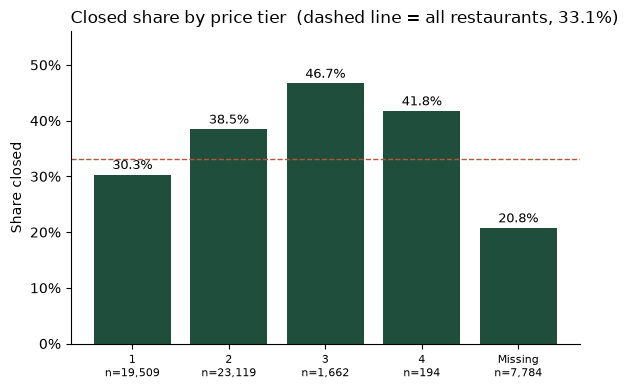

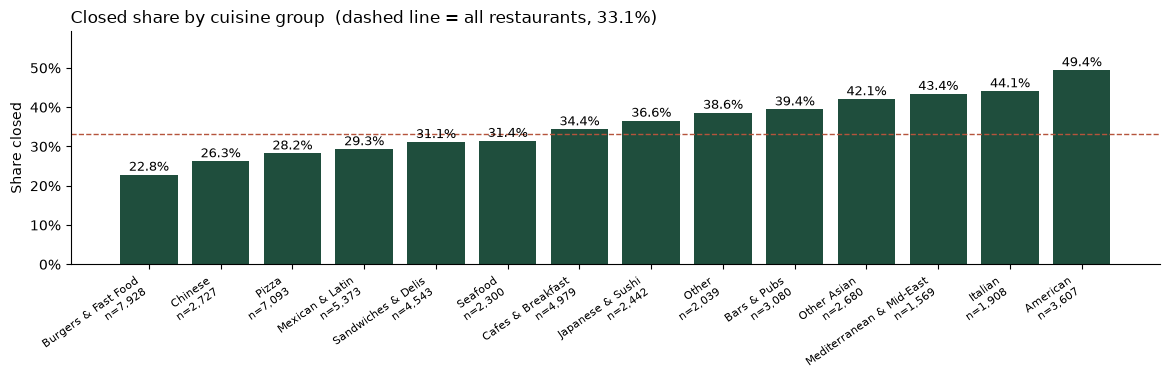

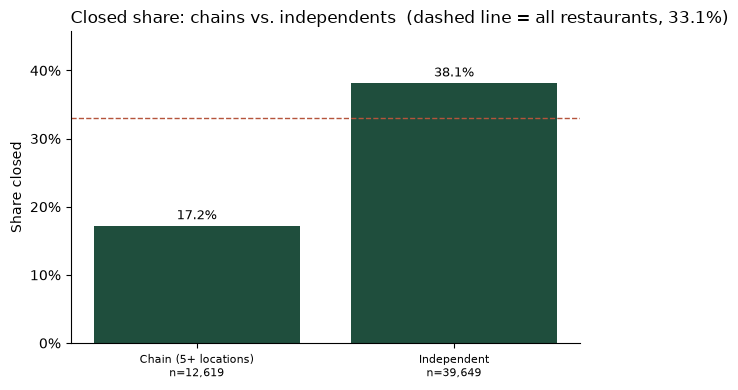

,rate,n
chain_label,,
Chain (5+ locations),0.171725,12619
Independent,0.381195,39649


In [18]:
OVERALL = df["closed"].mean()

def closure_bar(group_col, title, filename, order=None, rotate=0):
    t = df.groupby(group_col, observed=True)["closed"].agg(rate="mean", n="size")
    if order is not None:
        t = t.reindex(order)
    else:
        t = t.sort_values("rate")
    fig, ax = plt.subplots(figsize=(max(6, 0.7 * len(t) + 2), 4))
    bars = ax.bar(range(len(t)), t["rate"], color="#1f4e3d")
    ax.axhline(OVERALL, color="#b5543c", linestyle="--", linewidth=1)
    for i, (rate, n) in enumerate(zip(t["rate"], t["n"])):
        ax.text(i, rate + 0.01, f"{rate:.1%}", ha="center", fontsize=9)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([f"{lbl}\nn={n:,}" for lbl, n in zip(t.index, t["n"])], rotation=rotate, fontsize=8,
                       ha="right" if rotate else "center")
    ax.set_ylabel("Share closed")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    ax.set_ylim(0, max(t["rate"].max() * 1.2, OVERALL * 1.2))
    ax.set_title(f"{title}  (dashed line = all restaurants, {OVERALL:.1%})", loc="left", fontsize=12)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, filename), dpi=200)
    plt.show()
    return t

closure_bar("price_tier", "Closed share by price tier", "fig_price_tier.png", order=["1", "2", "3", "4", "Missing"])
closure_bar("cuisine_group", "Closed share by cuisine group", "fig_cuisine.png", rotate=35)
df["chain_label"] = df["is_chain"].map({0: "Independent", 1: f"Chain ({MAIN_CHAIN_CUTOFF}+ locations)"})
closure_bar("chain_label", "Closed share: chains vs. independents", "fig_chain.png")

Restaurants within 500 m, by quintile:


,min,max
density_quintile,,
Q1 fewest,0,6
Q2,6,12
Q3,12,21
Q4,21,44
Q5 most,44,560


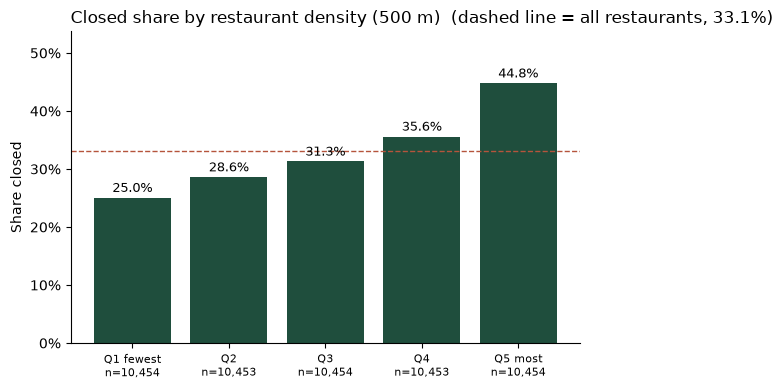

,rate,n
density_quintile,,
Q1 fewest,0.250430,10454
Q2,0.285947,10453
Q3,0.312990,10454
Q4,0.355974,10453
Q5 most,0.447771,10454


In [19]:
# Competition: five equal-sized groups by number of restaurants within the main radius
col = f"n_rest_{MAIN_RADIUS_M}m"
df["density_quintile"] = pd.qcut(df[col].rank(method="first"), 5, labels=["Q1 fewest", "Q2", "Q3", "Q4", "Q5 most"])
ranges = df.groupby("density_quintile", observed=True)[col].agg(["min", "max"])
print(f"Restaurants within {MAIN_RADIUS_M} m, by quintile:")
display(ranges)
closure_bar("density_quintile", f"Closed share by restaurant density ({MAIN_RADIUS_M} m)", "fig_density.png",
            order=["Q1 fewest", "Q2", "Q3", "Q4", "Q5 most"])

## Step 9 — Save outputs for the team

| File | For |
|---|---|
| `restaurants_clean.csv` | Modelling and validation notebooks |
| `data_dictionary.csv` | Report appendix |
| `missing_values.csv` | Report data section |
| `decisions_log.md` | Report data section and Q&A prep; ends with the recommended model inputs |
| `density_check_open_vs_all.csv` | Validation person (robustness of the density finding) |
| `metro_sizes.csv` | Validation person (choosing the held-out metro) |
| `fig_*.png` | Deck and report |

In [20]:
RECOMMENDED_INPUTS = ["price_tier", "cuisine_group", "is_chain", f"log_n_rest_{MAIN_RADIUS_M}m",
                      f"same_cuisine_share_{MAIN_RADIUS_M}m", "abs_price_gap", "price_gap_missing", "metro"]

keep = (["business_id", "name", "latitude", "longitude", "city", "state", "metro", "closed",
         "price_tier", "price_num", "cuisine_group", "is_chain"]
        + [f"is_chain_{k}" for k in CHAIN_CUTOFFS]
        + [f"n_rest_{r}m" for r in RADII_M] + [f"n_same_cuisine_{r}m" for r in RADII_M]
        + [f"nbr_mean_price_{MAIN_RADIUS_M}m", "price_gap"]
        # v2 model-ready features
        + [f"log_n_rest_{r}m" for r in RADII_M] + [f"log_n_same_cuisine_{r}m" for r in RADII_M]
        + [f"same_cuisine_share_{r}m" for r in RADII_M]
        + ["price_missing", "price_gap_missing", "price_gap_filled", "abs_price_gap"]
        # v2 robustness check only (not a model input)
        + [f"n_open_rest_{r}m" for r in RADII_M] + [f"log_n_open_rest_{r}m" for r in RADII_M])
clean = df[keep]
clean.to_csv(os.path.join(OUTPUT_DIR, "restaurants_clean.csv"), index=False)

descriptions = {
    "business_id": "Yelp business identifier",
    "name": "Restaurant name",
    "latitude": "Latitude (degrees)",
    "longitude": "Longitude (degrees)",
    "city": "City as listed on Yelp",
    "state": "State or province as listed on Yelp",
    "metro": "Nearest of 11 metro centres (used for the held-out-metro test)",
    "closed": "Target. 1 = permanently closed at the Yelp snapshot, 0 = open (1 - is_open)",
    "price_tier": "Yelp price range 1-4, or 'Missing'",
    "price_num": "Price range as a number 1-4 (NaN if missing); used for neighbour averages",
    "cuisine_group": "Cuisine group from categories, first match in a fixed priority list",
    "is_chain": f"1 if the normalized name appears at >= {MAIN_CHAIN_CUTOFF} restaurants",
    f"nbr_mean_price_{MAIN_RADIUS_M}m": f"Mean price tier of restaurants within {MAIN_RADIUS_M} m (those reporting price)",
    "price_gap": f"Own price tier minus nbr_mean_price_{MAIN_RADIUS_M}m",
}
for k in CHAIN_CUTOFFS:
    descriptions[f"is_chain_{k}"] = f"1 if the normalized name appears at >= {k} restaurants (robustness)"
for r in RADII_M:
    descriptions[f"n_rest_{r}m"] = f"Other restaurants within {r} m, open or closed"
    descriptions[f"n_same_cuisine_{r}m"] = f"Other restaurants of the same cuisine group within {r} m"
    descriptions[f"log_n_rest_{r}m"] = f"log(1 + n_rest_{r}m). Model input"
    descriptions[f"log_n_same_cuisine_{r}m"] = f"log(1 + n_same_cuisine_{r}m)"
    descriptions[f"same_cuisine_share_{r}m"] = f"n_same_cuisine_{r}m / n_rest_{r}m (0 if no neighbours). Model input"
    descriptions[f"n_open_rest_{r}m"] = f"Other OPEN restaurants within {r} m. Robustness check only, not a model input"
    descriptions[f"log_n_open_rest_{r}m"] = f"log(1 + n_open_rest_{r}m). Robustness check only"
descriptions.update({
    "price_missing": "1 if the restaurant reports no price tier",
    "price_gap_missing": "1 if price_gap cannot be computed (own or neighbour price missing)",
    "price_gap_filled": "price_gap with missing values set to 0 (use together with price_gap_missing)",
    "abs_price_gap": "Absolute value of price_gap_filled: distance from the local price level in either direction",
})

dictionary = pd.DataFrame({
    "variable": keep,
    "description": [descriptions[c] for c in keep],
    "type": [str(clean[c].dtype) for c in keep],
    "missing": [int(clean[c].isna().sum()) for c in keep],
    "example": [clean[c].dropna().iloc[0] if clean[c].notna().any() else "" for c in keep],
})
dictionary.to_csv(os.path.join(OUTPUT_DIR, "data_dictionary.csv"), index=False)
missing.to_csv(os.path.join(OUTPUT_DIR, "missing_values.csv"))

with open(os.path.join(OUTPUT_DIR, "decisions_log.md"), "w") as f:
    f.write("# Data preparation decisions\n\n")
    f.write(f"- Restaurants: {len(clean):,}; closed: {int(clean['closed'].sum()):,} ({clean['closed'].mean():.1%})\n")
    for d in decisions:
        f.write(f"- {d}\n")
    f.write("\n## Recommended model inputs (main specification)\n\n")
    for v in RECOMMENDED_INPUTS:
        f.write(f"- `{v}`\n")
    f.write("\nRobustness: other radii (250 m, 1 km), chain cutoffs 3 and 10, open-neighbour counts, leave-one-metro-out.\n")

print(f"Saved {len(clean):,} rows x {clean.shape[1]} columns to {OUTPUT_DIR}/restaurants_clean.csv")
print("Files in outputs:", sorted(os.listdir(OUTPUT_DIR)))
dictionary

Saved 52,268 rows x 42 columns to outputs/restaurants_clean.csv
Files in outputs: ['data_dictionary.csv', 'decisions_log.md', 'density_check_open_vs_all.csv', 'fig_chain.png', 'fig_cuisine.png', 'fig_density.png', 'fig_price_tier.png', 'metro_sizes.csv', 'missing_values.csv', 'restaurants_clean.csv']


,variable,description,type,missing,example
0,business_id,Yelp business identifier,str,0,MTSW4McQd7CbVtyjqoe9mw
1,name,Restaurant name,str,0,St Honore Pastries
2,latitude,Latitude (degrees),float64,0,39.955505
3,longitude,Longitude (degrees),float64,0,-75.155564
4,city,City as listed on Yelp,str,0,Philadelphia
5,state,State or province as listed on Yelp,str,0,PA
6,metro,Nearest of 11 metro centres (used for the held...,str,0,Philadelphia
7,closed,Target. 1 = permanently closed at the Yelp sna...,int64,0,0
8,price_tier,"Yelp price range 1-4, or 'Missing'",str,0,1
9,price_num,Price range as a number 1-4 (NaN if missing); ...,float64,7784,1.0


## Hand-off checklist

- [ ] Restaurant count and closure rate match the pitch deck (or the difference is explained)
- [ ] No restaurants flagged as far from every metro, or the metro list was updated
- [ ] Top cuisine tags reviewed and `CUISINE_GROUPS` adjusted if needed
- [ ] Largest chains look like real chains
- [ ] Log counts are much less skewed, and the model-ready competition variables correlate well below 0.8
- [ ] Density check: does the closed share still rise from Q1 to Q5 with open neighbours only? Tell the validation person either way
- [ ] Recommended model inputs (end of `decisions_log.md`) sent to the modelling person
- [ ] `outputs/` folder shared with the team